In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS=3
EPOCHS=15

In [3]:
input_shape = (640, 640, 3)

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/EC_Classification/NS',
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 1074 files belonging to 3 classes.


In [5]:
class_names = dataset.class_names
class_names

['Dysplasia', 'Normal', 'SCC']

In [6]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())

(32, 640, 640, 3)
[0 0 2 2 0 0 1 1 1 0 2 0 1 1 2 0 0 2 1 0 1 2 1 2 1 0 0 0 2 0 1 2]


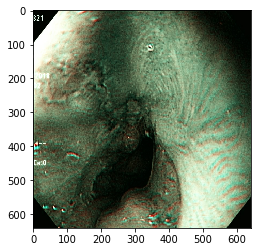

In [7]:
plt.imshow(image_batch[4].numpy().astype("uint8"))

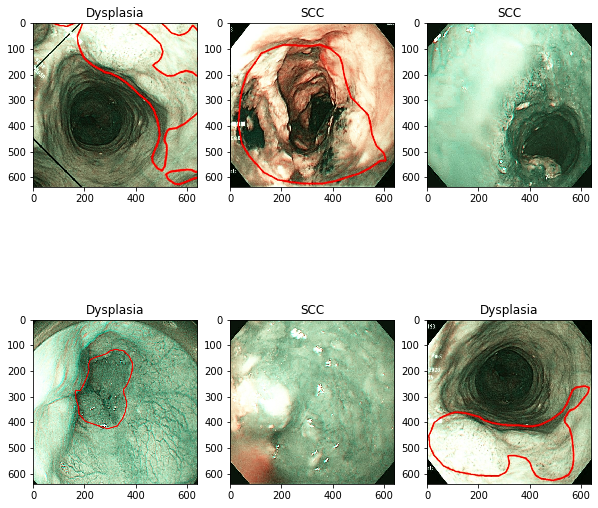

In [8]:
plt.figure(figsize=(10, 10))
for image_batch, labels_batch in dataset.take(1):
    for i in range (6):
        plt.subplot(2,3,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])

In [9]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.05, test_split=0.15, shuffle=True, shuffle_size=10):
    assert (train_split + test_split + val_split) == 1
    ds_size = len(ds)
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)
    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    return train_ds, val_ds, test_ds

In [10]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [11]:
len(train_ds)

27

In [12]:
len(test_ds)

6

In [13]:
resize_and_rescale = tf.keras.Sequential([
  layers.experimental.preprocessing.Resizing(IMAGE_SIZE, IMAGE_SIZE),
  layers.experimental.preprocessing.Rescaling(1./255),
])

In [14]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=[640,640,3]),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=input_shape)

In [15]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [16]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (32, 640, 640, 3)         0         
                                                                 
 conv2d (Conv2D)             (32, 638, 638, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2D  (32, 319, 319, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (32, 317, 317, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (32, 158, 158, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (32, 156, 156, 64)       

In [17]:
model.fit(
    train_ds,
    verbose=1,
    epochs=10,
)

Epoch 1/10
27/27 [==============================] - 374s 14s/step - loss: 1.1544 - accuracy: 0.4062
Epoch 2/10
27/27 [==============================] - 330s 12s/step - loss: 0.9476 - accuracy: 0.5541
Epoch 3/10
27/27 [==============================] - 361s 13s/step - loss: 0.7808 - accuracy: 0.6635
Epoch 4/10
27/27 [==============================] - 368s 14s/step - loss: 0.5619 - accuracy: 0.7824
Epoch 5/10
27/27 [==============================] - 340s 12s/step - loss: 0.3892 - accuracy: 0.8530
Epoch 6/10
27/27 [==============================] - 368s 14s/step - loss: 0.2805 - accuracy: 0.8953
Epoch 7/10
27/27 [==============================] - 348s 13s/step - loss: 0.2024 - accuracy: 0.9363
Epoch 8/10
27/27 [==============================] - 338s 12s/step - loss: 0.1464 - accuracy: 0.9618
Epoch 9/10
27/27 [==============================] - 359s 13s/step - loss: 0.1064 - accuracy: 0.9671
Epoch 10/10
27/27 [==============================] - 362s 13s/step - loss: 0.0758 - accuracy: 0.9776

first image to predict
actual label: Normal
1/1 [==============================] - 3s 3s/step
predicted label: Normal


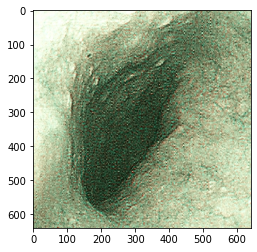

In [18]:
import numpy as np
for image_batch, labels_batch in test_ds.take(1):
    first_image = image_batch[1].numpy().astype('uint8')
    first_label = labels_batch[1].numpy()
    print("first image to predict")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])
    batch_prediction = model.predict(image_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[1])])

In [19]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)
    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 [==============================] - 0s 199ms/step


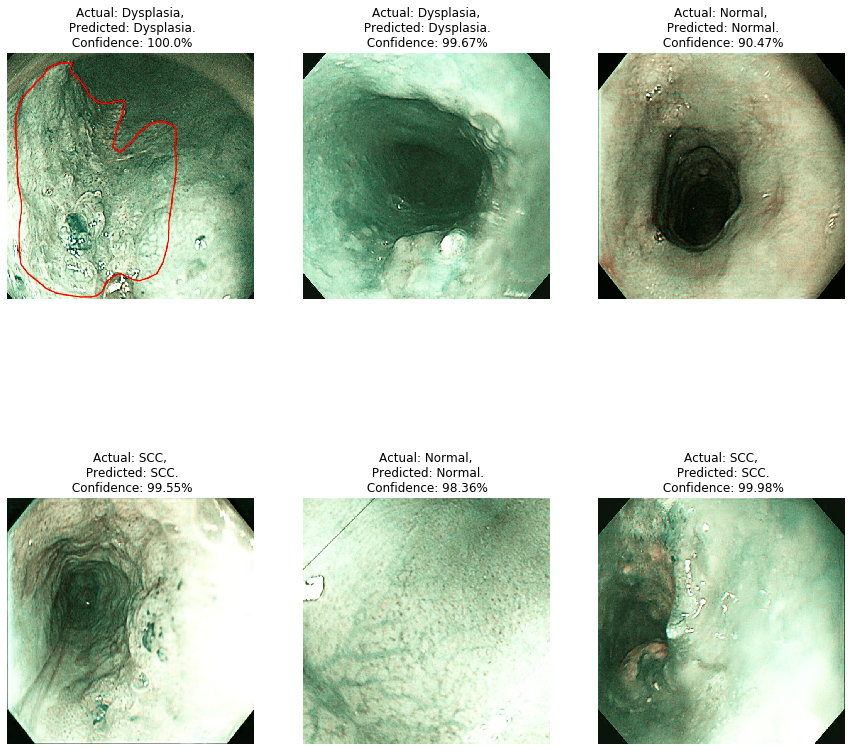

In [20]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        plt.axis("off")

In [21]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
y_pred = []
y_true = []
for images, labels in test_ds:
    predictions = model.predict(images)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())
y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 [==============================] - 3s 3s/step


In [22]:
report = classification_report(y_true, y_pred, target_names=class_names)
print("Classification Report:\n\n", report)

Classification Report:

               precision    recall  f1-score   support

   Dysplasia       1.00      1.00      1.00        63
      Normal       1.00      1.00      1.00        54
         SCC       1.00      1.00      1.00        61

    accuracy                           1.00       178
   macro avg       1.00      1.00      1.00       178
weighted avg       1.00      1.00      1.00       178



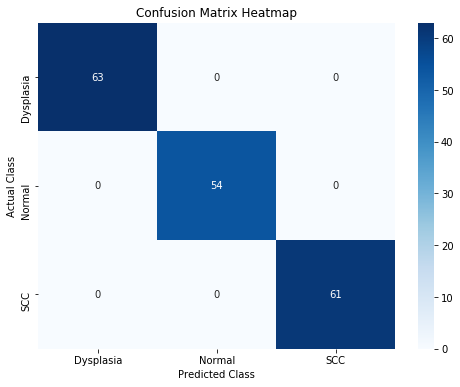

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [25]:
model.save('/home/smartcity_sp7/EC_Classification/CNN-SAVE')

INFO:tensorflow:Assets written to: /home/smartcity_sp7/EC_Classification/CNN-SAVE/assets


INFO:tensorflow:Assets written to: /home/smartcity_sp7/EC_Classification/CNN-SAVE/assets


In [26]:
model.save_weights('/home/smartcity_sp7/EC_Classification/CNN-SAVE weight')